# 01 · Fear gauge de um market maker real na Hyperliquid

Pergunta: **qual é a aversão a risco (γ) que explica as cotações de um market maker real, e onde o modelo de livro-texto deixa de funcionar?**

Os dados vêm de cerca de 20 minutos de gravação ao vivo feita com `python -m fear_gauge.recorder`. O primeiro minuto é descartado, porque o livro de ordens ainda está sendo montado. Ela contém as cotações da carteira, os fills e o inventário, além do melhor preço de compra e venda do mercado (bbo). O notebook `00_validacao_simulada` mostra que o γ medido pelo deslocamento das cotações é confiável e que o γ medido pelo spread não é.

In [1]:
import sys; sys.path.insert(0, "../src")
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fear_gauge.glft import MarketParams
from fear_gauge.simulate import simulate_mm
from fear_gauge.estimate import estimate_gamma, fit_intensity, rolling_gauge, model_quotes_check
from fear_gauge import breaks, plots

pd.set_option("display.float_format", "{:.4g}".format)

from pathlib import Path
from fear_gauge.dataset import build_panel, load_context

PERIODO = None
JANELA, PASSO = "5min", "1min"

gravacoes = sorted((Path("..") / "data" / "gravacoes").glob("*/alvo.json"), key=lambda p: p.stat().st_mtime)
PASTA = gravacoes[-1].parent
panel, info = build_panel(PASTA)
panel = panel.iloc[60:]
if PERIODO:
    panel = panel[panel.index >= panel.index[-1] - pd.Timedelta(PERIODO)]
info.update({"inicio": str(panel.index[0]), "fim": str(panel.index[-1]), "horas": len(panel) / 3600,
             "fills_maker": int(panel["fill_bid"].sum() + panel["fill_ask"].sum()),
             "fracao_dois_lados": float((panel["bid"].notna() & panel["ask"].notna()).mean())})
pd.Series(info)

user                    0x4e60e3a4a32d63d245aa4e4ce304b4254b088f95
coin                                                          HYPE
fonte_cotacoes                                        orderUpdates
inicio                                         2026-11-27 00:44:48
fim                                            2026-11-27 01:06:30
horas                                                       0.3619
fills_maker                                                    281
fills_total                                                    289
posicao_inicial_api                                         -33.99
fracao_cotacao_atual                                             1
fracao_dois_lados                                           0.8803
dtype: object

## 1. Os dados

Antes de estimar qualquer coisa, confiro a qualidade: quantas horas, quantos fills como maker, quanto tempo a carteira cotou dos dois lados e de onde vieram as cotações.

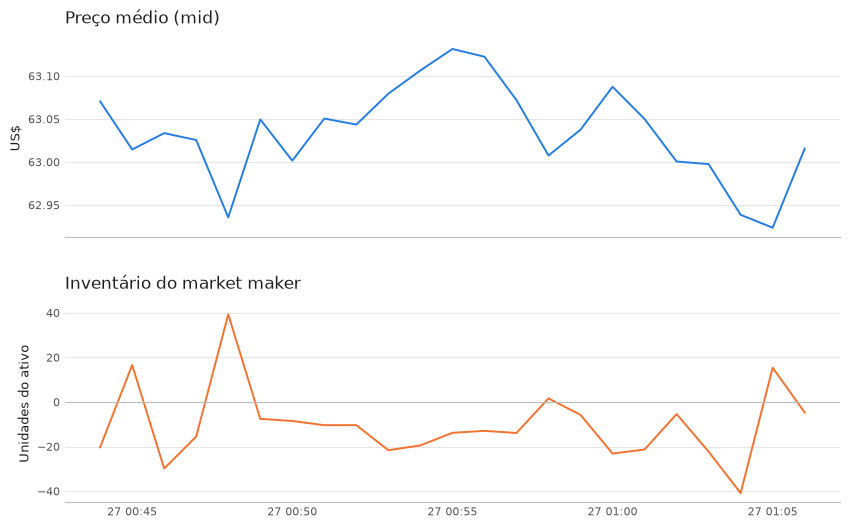

phi             -0.1533
meia_vida_min         0
q_desvio          16.77
q_min            -40.89
q_max             39.29
dtype: float64

In [2]:
plots.inventory_and_mid(panel)
plt.show()
breaks.inventory_half_life(panel)

## 2. Intensidade de execução

Quanto mais longe do mid a cotação está, menos ela é executada. O modelo supõe que essa queda é exponencial. Comparo com uma queda em lei de potência e com o ajuste separado para compra e venda.

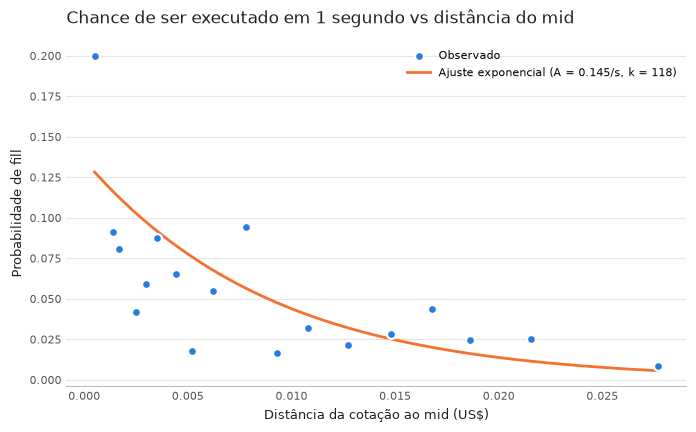

,A,k,loglik,aic,n
exponencial,0.1455,117.6,-582.4,1169,2439
potencia,0.002155,0.602,-568.1,1140,2439
so_bid,0.1451,133.4,-340,683.9,1193
so_ask,0.1574,118,-242,488.1,1246


In [3]:
intensidade = breaks.intensity_shape(panel)
fit = fit_intensity(panel)
plots.intensity_curve(panel, fit)
plt.show()
intensidade[["A", "k", "loglik", "aic", "n"]]

## 3. γ do período inteiro

Duas formas de medir. Se o modelo estiver certo, elas concordam.

sigma            0.006732
A                  0.1455
k                   117.6
delta                6.34
skew            0.0001869
skew_se         2.321e-05
spread            0.01638
gamma_skew         0.0614
gamma_skew_lo     0.03517
gamma_skew_hi     0.09484
gamma_spread          NaN
n_two_sided          1147
dtype: float64

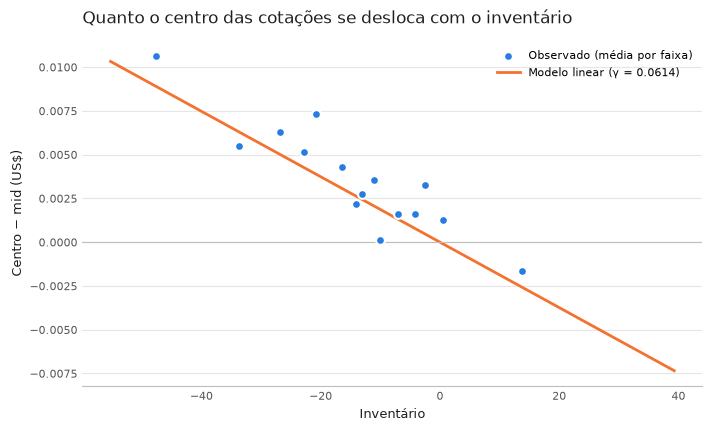

skew_previsto      0.0001869
skew_observado     0.0001869
spread_previsto      0.01816
spread_observado     0.01638
dtype: float64

In [4]:
est = estimate_gamma(panel, intensity=fit)
display(est.as_series())
plots.skew_vs_inventory(panel, est)
plt.show()
model_quotes_check(est)

## 4. Fear gauge

γ estimado em janelas de 5 minutos, andando de 1 em 1 minuto, comparado com a volatilidade. No modelo, γ é constante: o deslocamento das cotações deveria crescer na mesma proporção que a volatilidade (inclinação 1) e a elasticidade de γ deveria ser zero. Se ela for positiva, o market maker tem mais medo em mercado agitado do que o modelo prevê.

Cuidado: se a volatilidade quase não muda entre as janelas, o próprio ruído da estimativa de σ cria uma relação falsa. Por isso o teste mede a confiabilidade de σ e só é marcado como conclusivo quando ela passa de 0,5.

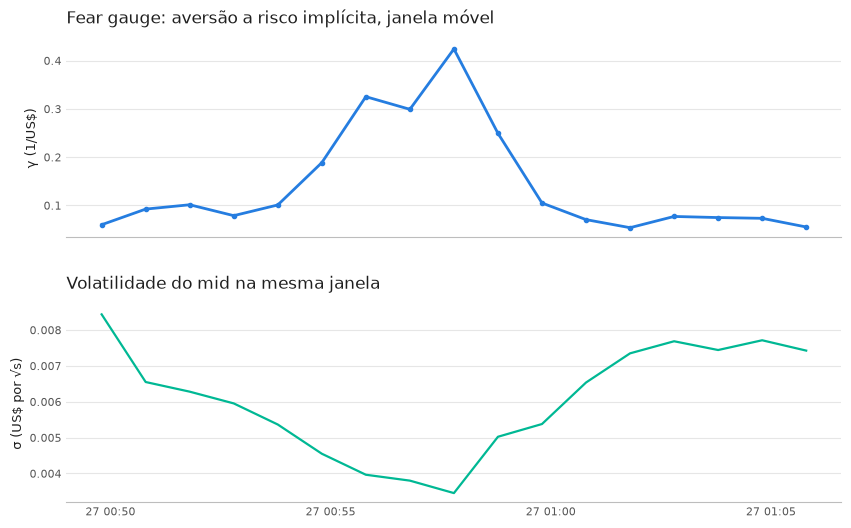

inclinacao_skew_sigma     -0.1535
elasticidade_gamma         -2.307
pvalor                  1.602e-47
confiabilidade_sigma       0.9777
conclusivo                   True
n                              17
dtype: object

,sigma,n_mid,skew,skew_pvalor,gamma,spread,inventario_abs,fills
count,17,17,17,17,17,17,17,17
mean,0.006053,300,0.0002223,9.871e-05,0.1429,0.01626,16.08,61.76
std,0.001532,0,2.687e-05,0.0003582,0.1127,0.001503,3.363,19.97
min,0.003453,300,0.0001873,1.193e-104,0.05389,0.01404,11.22,34
25%,0.005023,300,0.0001954,1.372e-14,0.07331,0.0149,15.12,51
50%,0.00628,300,0.0002242,3.874e-10,0.09239,0.01631,15.51,58
75%,0.007425,300,0.000234,1.494e-08,0.1886,0.01755,16.41,78
max,0.008435,300,0.0002817,0.001483,0.4241,0.01839,24.13,94


In [5]:
gauge = rolling_gauge(panel, window=JANELA, step=PASSO, intensity=fit, min_rows=150)
plots.gauge(gauge)
plt.show()
display(breaks.gamma_vs_vol(gauge, overlap=5))
gauge.describe()

In [6]:
contexto = load_context(PASTA)
if not contexto.empty:
    juntos = gauge.join(contexto.resample(PASSO).last(), how="left")
    display(juntos[["gamma", "sigma", "funding", "open_interest"]].corr(method="spearman").round(2))

,gamma,sigma,funding,open_interest
gamma,1,-0.87,NaN,NaN
sigma,-0.87,1,NaN,NaN
funding,NaN,NaN,NaN,NaN
open_interest,NaN,NaN,NaN,NaN


## 5. Onde o modelo quebra

### 5.1 O deslocamento é linear no inventário?
O modelo diz que é uma reta. Market makers reais costumam ter limites: perto do limite, param de cotar de um lado.

In [7]:
faixas, teste = breaks.skew_shape(panel)
display(teste)
faixas

coef_q      -0.0001784
coef_q3     -1.072e-06
pvalor_q3       0.6983
dtype: float64

,q_medio,centro_medio,so_bid,so_ask,dois_lados,segundos
faixa_q,,,,,,
"(-55.241, -33.26]",-43.96,0.009257,0.08511,0.09929,0.8156,141
"(-33.26, -23.77]",-27.98,0.005941,0.08759,0.0365,0.8686,137
"(-23.77, -21.66]",-22.44,0.005837,0.02362,0.2126,0.7244,127
"(-21.66, -15.75]",-18.57,0.005732,0.008,0.008,0.984,125
"(-15.75, -13.86]",-14.17,0.002323,0.02239,0.1418,0.8209,134
"(-13.86, -10.85]",-12.1,0.002769,0.07087,0.007874,0.9213,127
"(-10.85, -7.59]",-9.729,0.001665,0.008065,0.05645,0.9274,124
"(-7.59, -4.07]",-5.161,0.001798,0.007092,0.1135,0.8794,141
"(-4.07, -0.42]",-2.521,0.002548,0.008403,0.01681,0.9664,119


### 5.2 Seleção adversa
O modelo supõe que o preço não anda contra o market maker depois de um fill. Se ele anda, quem executa contra ele está mais informado.

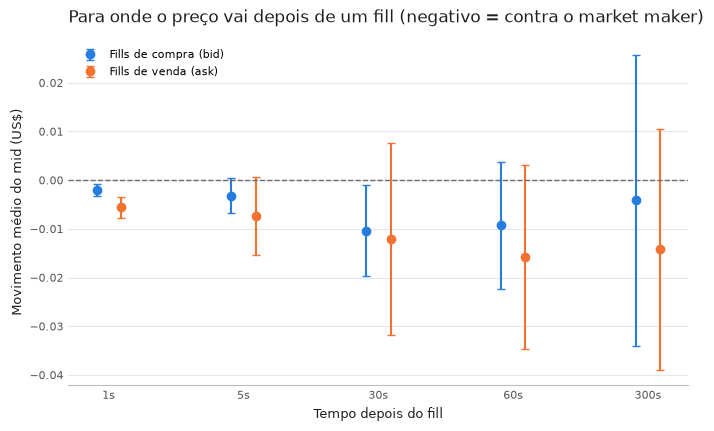

,lado,horizonte_s,movimento_medio,erro_padrao,pvalor,n
0,compra (bid),1,-0.002028,0.0006016,0.0007482,107
1,compra (bid),5,-0.003184,0.001837,0.08304,106
2,compra (bid),30,-0.01038,0.004738,0.02842,106
3,compra (bid),60,-0.009279,0.006621,0.1611,104
4,compra (bid),300,-0.004134,0.01525,0.7863,86
5,venda (ask),1,-0.005581,0.001076,2.166e-07,68
6,venda (ask),5,-0.007455,0.004082,0.06777,67
7,venda (ask),30,-0.01203,0.01007,0.2324,66
8,venda (ask),60,-0.01577,0.00965,0.1023,64
9,venda (ask),300,-0.01422,0.01261,0.2596,53


In [8]:
m = breaks.markouts(panel)
plots.markout_chart(m)
plt.show()
m

### 5.3 Tick mínimo
Se o spread vive encostado em 1 ou 2 ticks, ele é definido pelo arredondamento, não pela aversão a risco.

In [9]:
breaks.tick_pinning(panel)

tick                       0.001
spread_medio_em_ticks      16.38
fracao_spread_1_tick    0.007847
fracao_dois_lados         0.8803
dtype: float64

## 6. Conclusões (HYPE, 26/11/2026, cerca de 22 minutos de gravação)

**Resumo:** consegui medir a aversão a risco desse market maker (γ ≈ 0,06), mas o modelo de livro-texto só explica uma parte do comportamento dele. Em quatro pontos importantes, ele faz algo que o modelo não prevê.

### O que deu certo
- **O deslocamento pelo inventário existe e é uma reta.** Quando ele fica vendido (inventário negativo), sobe as cotações para recomprar, e o contrário quando fica comprado. O teste de curvatura não achou nada (p-valor de 0,70).
- **Dá para tirar um γ desse deslocamento:** cerca de 0,06, com intervalo de 0,035 a 0,095.
- **O inventário volta para perto de zero muito rápido,** em menos de um minuto, mesmo oscilando entre −40 e +40 HYPE.
- **O tick mínimo não atrapalha.** O spread médio é de 16 ticks, então ele não fica preso no arredondamento.

### Onde o modelo quebra
- **O spread é apertado demais para o modelo.** Mesmo com aversão a risco zero, o modelo exigiria um spread de pelo menos 0,017 US\$, e ele cota com 0,0164 US\$. Nenhum valor de γ explica isso. Algumas explicações possíveis, que ainda não testei: ele recebe rebate por ser maker, prevê o preço usando outras corretoras, ou a forma da intensidade de execução está errada (ver abaixo).
- **Há seleção adversa.** Um segundo depois de cada execução, o preço já andou contra ele: em média 0,002 US\$ depois das compras e 0,006 US\$ depois das vendas, os dois com p-valor abaixo de 0,001. Isso é uma parte relevante do meio spread (cerca de 0,008 US\$). O modelo supõe que isso não acontece.
- **A chance de execução não cai de forma exponencial.** Uma curva em lei de potência se ajusta melhor aos dados (AIC 1140 contra 1169).
- **O "medo" não sobe com a volatilidade, ele cai.** O modelo prevê que o deslocamento por unidade de inventário cresce junto com a volatilidade. Nos dados, ele ficou praticamente fixo em preço enquanto a volatilidade mais que dobrou. Por isso o γ implícito variou de 0,05 a 0,42 e andou na direção contrária da volatilidade (correlação de −0,87). A leitura mais provável é que ele usa uma regra fixa de deslocamento, e não um cálculo de risco que se ajusta ao mercado.
- **Ele tira as cotações nos saltos de preço.** Em cerca de 12% do tempo ficou cotando só de um lado. Isso acontece mais quando o preço salta (19% do tempo, contra 11% no resto) e quase não tem relação com o tamanho do inventário (correlação de 0,09). O modelo supõe cotação contínua.

### Por que ainda não dá para confiar
- **São só 22 minutos e 281 execuções.** As janelas de 5 minutos do fear gauge se sobrepõem, então na prática são umas 4 medidas independentes. O p-valor do teste de volatilidade fica muito otimista com tão poucas janelas.
- **O inventário em HYPE não é o risco real dele.** Esse market maker cota cerca de 170 mercados ao mesmo tempo. Ele provavelmente pensa no risco da carteira inteira, e o modelo olha uma moeda isolada.
- **É um market maker e um período.** Outro horário ou outro ativo podem dar um resultado diferente.

### Próximos passos
Gravar algumas horas em horários diferentes para ter mais janelas independentes e testar as explicações para o spread apertado: comparar com o preço da Binance para ver se ele antecipa o mercado e descontar o rebate de maker.

### Limitações
- O γ aqui é o número que faz o modelo reproduzir as cotações, não uma medida direta do que o operador sente.
- A volatilidade e a intensidade de execução são estimadas, e o erro delas passa para o γ.
- O primeiro minuto da gravação foi descartado porque o livro de ordens ainda estava sendo montado.

*Este projeto é um estudo, não uma recomendação de investimento.*